# 02 · February vs December (2022–2024)

**EDA Steps 3–5.** This notebook compares low-traffic February trips with high-traffic December trips, pooling 2022–2024. 2025 is kept aside for notebook 03.

* **Data:** the 250K-per-month sample from notebook 01 (750K Feb + 750K Dec trips), plus the full-data summary tables where noted
* **Tip %** $= \dfrac{\text{tip\_amount}}{\text{fare\_amount}} \times 100$
* **Colors:** February is always blue and December is always orange
* With this many trips, almost every difference is statistically significant. Judge results by **size**: `MEANINGFUL_GAP` below sets what counts as a gap worth talking about (agree on it as a team).

📊 marks cells that make a chart; charts are saved to `figures/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import taxi_utils as tu

tu.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
MEANINGFUL_GAP = 0.5      # percentage points of tip %
MONTHS2 = ["Feb", "Dec"]

sample = pd.concat([pd.read_parquet(tu.SAMPLE / f"sample_{m}.parquet") for m in tu.MONTHS],
                   ignore_index=True)
s = sample[sample.year.isin(tu.EDA_YEARS)].copy()
feb, dec = s[s.month_name == "Feb"], s[s.month_name == "Dec"]

full_month = pd.read_csv(tu.PROCESSED / "full_by_month.csv")
full_day = pd.read_csv(tu.PROCESSED / "full_by_day.csv")
full_hour = pd.read_csv(tu.PROCESSED / "full_by_hour.csv")
full_zone = pd.read_csv(tu.PROCESSED / "full_by_zone.csv")
print(f"{len(s):,} sampled trips in 2022-2024 ({len(feb):,} Feb, {len(dec):,} Dec)")

1,500,000 sampled trips in 2022-2024 (750,000 Feb, 750,000 Dec)


---
# Step 3 · Tip distribution
## 3a · How tip % is distributed 📊

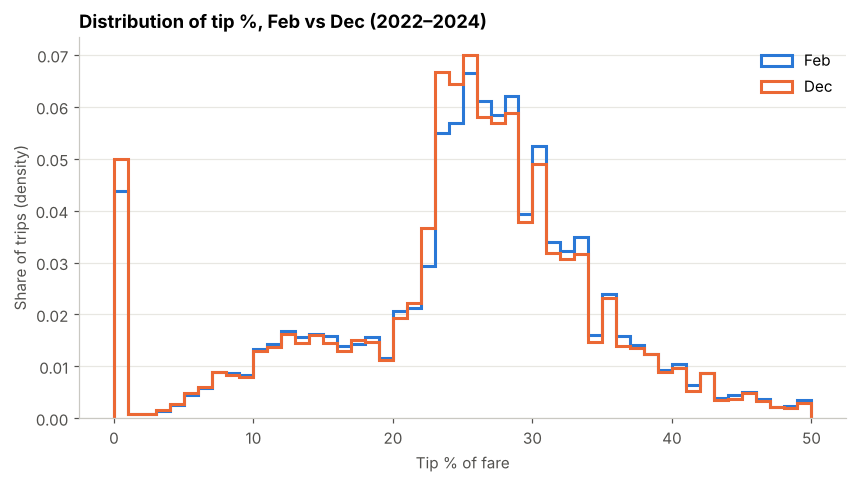

In [2]:
bins = np.arange(0, 51, 1)
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, d in [("Feb", feb), ("Dec", dec)]:
    ax.hist(d.tip_pct, bins=bins, density=True, histtype="step", linewidth=2,
            color=tu.MONTH_COLORS[name], label=name)
ax.set_xlabel("Tip % of fare")
ax.set_ylabel("Share of trips (density)")
ax.set_title("Distribution of tip %, Feb vs Dec (2022–2024)")
ax.legend()
tu.save_fig(fig, "03a_tip_distribution")
plt.show()

## 3b · Zero-tip share by year 📊 (full data)

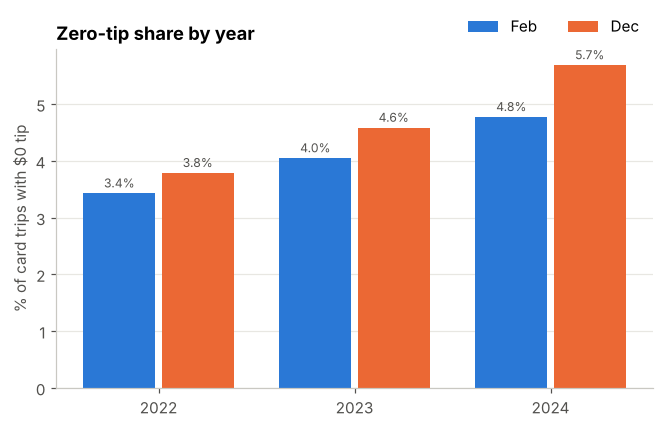

In [3]:
zt = full_month[full_month.year.isin(tu.EDA_YEARS)]
fig, ax = plt.subplots(figsize=(7, 4))
tu.grouped_bar(ax, zt, "year", "month_name", "zero_tip_pct", tu.MONTH_COLORS,
               order=tu.EDA_YEARS, groups=MONTHS2)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", fontsize=8, color=tu.INK_2, padding=2)
ax.set_ylabel("% of card trips with $0 tip")
ax.set_title("Zero-tip share by year")
tu.save_fig(fig, "03b_zero_tip_by_year")
plt.show()

## 3c · Bunching at preset tip buttons 📊

Card screens offer preset tip buttons, so tips may pile up at round percentages. The presets may be calculated on the fare **or** on the fare plus surcharges, so both denominators are shown. Spikes that line up with 20/25/30% on one denominator but not the other tell you which base the screen uses. Use this to decide on the tip % definition and a classification threshold.

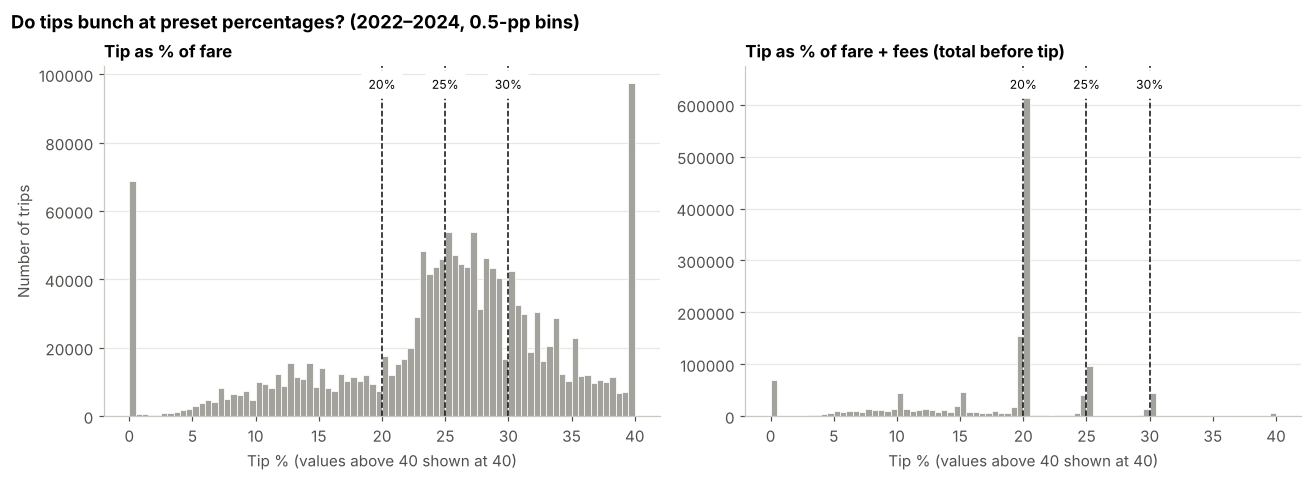

In [4]:
bins = np.arange(0, 40.5, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, title in [(axes[0], "tip_pct", "Tip as % of fare"),
                       (axes[1], "tip_pct_total", "Tip as % of fare + fees (total before tip)")]:
    ax.hist(s[col].clip(upper=40), bins=bins, color=tu.NEUTRAL, edgecolor="white", linewidth=0.5)
    for p in (20, 25, 30):
        ax.axvline(p, color=tu.INK, linestyle="--", linewidth=1)
        ax.text(p, ax.get_ylim()[1] * 0.97, f"{p}%", ha="center", va="top", fontsize=8,
                backgroundcolor="white")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Tip % (values above 40 shown at 40)")
axes[0].set_ylabel("Number of trips")
fig.tight_layout()
fig.suptitle("Do tips bunch at preset percentages? (2022–2024, 0.5-pp bins)", y=1.03,
             x=0.01, ha="left", fontweight="bold")
tu.save_fig(fig, "03c_preset_bunching")
plt.show()

In [5]:
# Share of trips within +/-0.5 pp of each preset, for both denominators
rows = []
for col in ["tip_pct", "tip_pct_total"]:
    for p in (20, 25, 30):
        rows.append({"denominator": col, "preset": f"{p}%",
                     "share_of_trips_%": (s[col].sub(p).abs() <= 0.5).mean() * 100})
pd.DataFrame(rows).pivot(index="preset", columns="denominator", values="share_of_trips_%")

denominator,tip_pct,tip_pct_total
preset,,
20%,1.67,53.04
25%,6.81,9.12
30%,3.96,3.89


## 3d · Summary statistics by month (full data)

In [6]:
tbl = (full_month[full_month.year.isin(tu.EDA_YEARS)]
       .set_index(["year", "month_name"])
       [["n", "mean", "median", "sd", "zero_tip_pct", "tip20_pct"]]
       .rename(columns={"mean": "mean tip %", "median": "median tip %", "sd": "sd",
                        "zero_tip_pct": "zero tip %", "tip20_pct": "tip >= 20%"}))
tbl.to_csv(tu.DOCS / "step3_tip_summary_by_month.csv")
tbl

n  mean tip %  median tip %    sd  zero tip %  \
year month_name                                                        
2022 Feb         2240280       26.30         26.84 10.68        3.43   
     Dec         2464551       25.66         26.17 10.67        3.79   
2023 Feb         2245271       25.01         26.13 10.64        4.05   
     Dec         2516672       24.96         25.93 10.63        4.58   
2024 Feb         2295031       25.09         26.25 10.75        4.77   
     Dec         2673968       24.70         25.70 10.98        5.69   

                 tip >= 20%  
year month_name              
2022 Feb              79.25  
     Dec              78.47  
2023 Feb              75.53  
     Dec              76.61  
2024 Feb              76.11  
     Dec              75.82

---
# Step 4 · How Feb and Dec trips differ (trip characteristics only)
## 4a · Daily trip volume 📊 (full data)

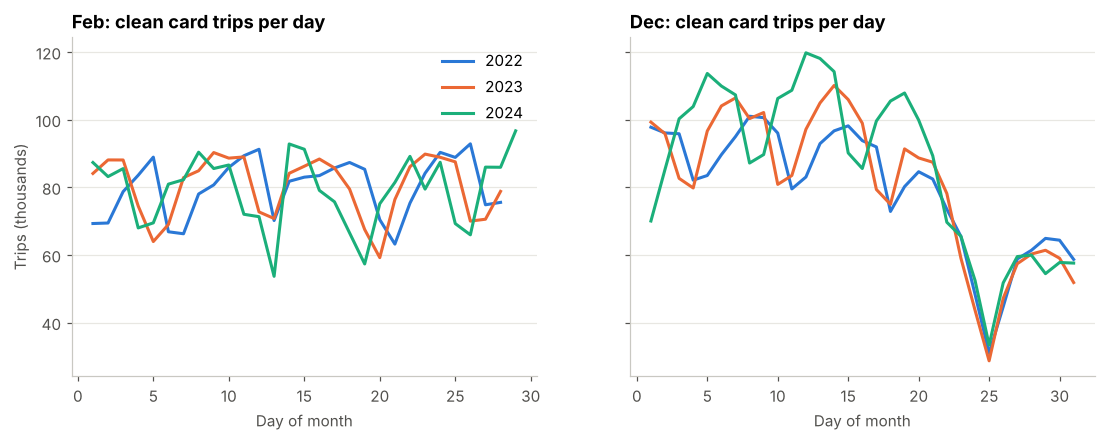

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, mn in zip(axes, MONTHS2):
    for y in tu.EDA_YEARS:
        d = full_day[(full_day.year == y) & (full_day.month_name == mn)]
        ax.plot(d.day, d.trips / 1000, color=tu.YEAR_COLORS[y], label=str(y))
    ax.set_title(f"{mn}: clean card trips per day")
    ax.set_xlabel("Day of month")
axes[0].set_ylabel("Trips (thousands)")
axes[0].legend()
tu.save_fig(fig, "04a_daily_volume")
plt.show()

## 4b · When trips happen: share of trips by hour 📊 (full data)

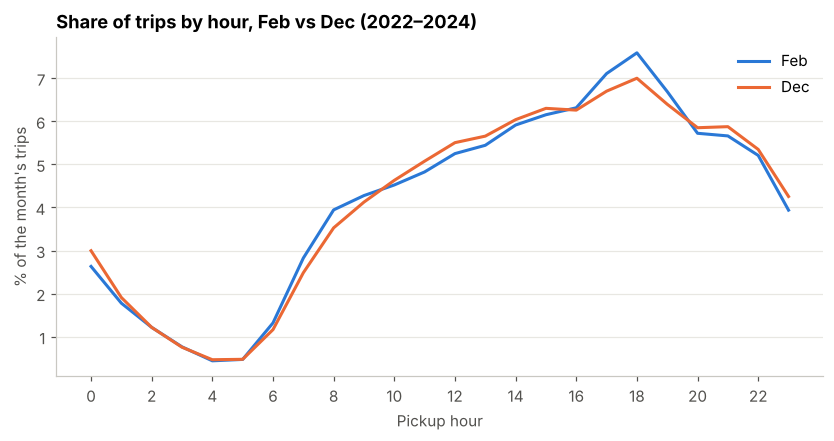

In [8]:
h = (full_hour[full_hour.year.isin(tu.EDA_YEARS)]
     .groupby(["month_name", "hour"]).n.sum().reset_index())
h["share"] = h.n / h.groupby("month_name").n.transform("sum") * 100
fig, ax = plt.subplots(figsize=(9, 4))
for mn in MONTHS2:
    d = h[h.month_name == mn]
    ax.plot(d.hour, d.share, color=tu.MONTH_COLORS[mn], label=mn)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Pickup hour")
ax.set_ylabel("% of the month's trips")
ax.set_title("Share of trips by hour, Feb vs Dec (2022–2024)")
ax.legend()
tu.save_fig(fig, "04b_trips_by_hour")
plt.show()

## 4c · Distance, fare and duration 📊

Box plots hide outliers (whiskers = 1.5 × IQR) so the main shape is readable.

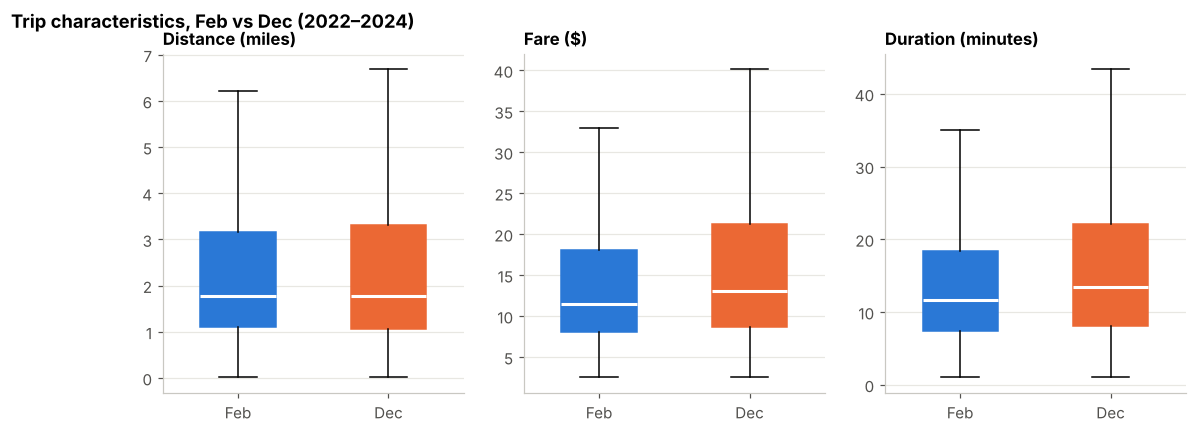

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col, label in [(axes[0], "trip_distance", "Distance (miles)"),
                       (axes[1], "fare_amount", "Fare ($)"),
                       (axes[2], "duration_min", "Duration (minutes)")]:
    bp = ax.boxplot([feb[col], dec[col]], tick_labels=MONTHS2, showfliers=False,
                    patch_artist=True, widths=0.5, medianprops={"color": "white", "linewidth": 2})
    for patch, mn in zip(bp["boxes"], MONTHS2):
        patch.set_facecolor(tu.MONTH_COLORS[mn])
        patch.set_edgecolor(tu.MONTH_COLORS[mn])
    ax.set_title(label, fontsize=11)
fig.suptitle("Trip characteristics, Feb vs Dec (2022–2024)", x=0.01, ha="left", fontweight="bold")
tu.save_fig(fig, "04c_trip_characteristics")
plt.show()

## 4d · Where trips start: borough mix and airport share 📊

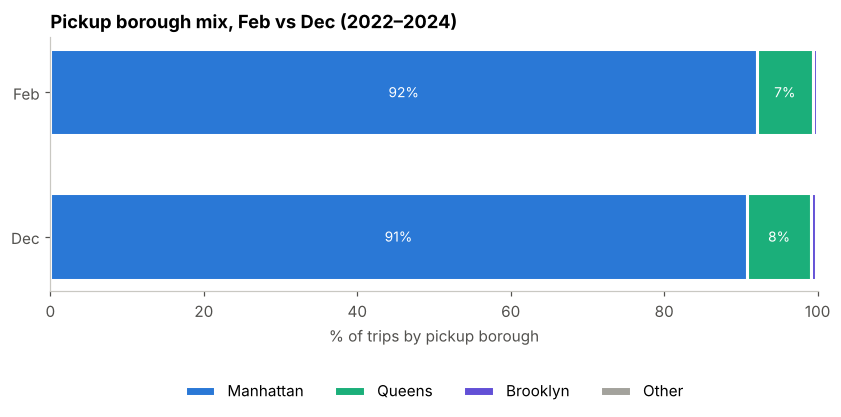

,is_airport,is_weekend,is_night,same_zone
month_name,,,,
Feb,8.36,27.44,16.46,3.55
Dec,10.05,28.19,17.43,3.76


In [10]:
s["pu_group"] = s.pu_borough.where(s.pu_borough.isin(["Manhattan", "Queens", "Brooklyn"]), "Other")
mix = pd.crosstab(s.month_name, s.pu_group, normalize="index").loc[MONTHS2] * 100
mix = mix[["Manhattan", "Queens", "Brooklyn", "Other"]]
colors = dict(zip(mix.columns, ["#2a78d6", "#1baf7a", "#6250d6", tu.NEUTRAL]))

fig, ax = plt.subplots(figsize=(9, 3))
left = np.zeros(len(mix))
for col in mix.columns:
    ax.barh(mix.index, mix[col], left=left, color=colors[col], edgecolor="white",
            linewidth=2, label=col, height=0.6)
    for i, v in enumerate(mix[col]):
        if v > 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    left += mix[col].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.grid(False)
ax.set_xlabel("% of trips by pickup borough")
ax.set_title("Pickup borough mix, Feb vs Dec (2022–2024)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.3))
tu.save_fig(fig, "04d_borough_mix")
plt.show()

s.groupby("month_name")[["is_airport", "is_weekend", "is_night", "same_zone"]].mean().loc[MONTHS2] * 100

## 4e · Trip characteristics: size of the Feb vs Dec gap

`diff` = Dec − Feb. Cohen's d below about 0.1 is a negligible difference.

In [11]:
rows = []
for col in ["trip_distance", "fare_amount", "duration_min", "speed_mph", "passenger_count"]:
    r = tu.diff_ci(feb[col].dropna(), dec[col].dropna())
    rows.append({"variable": col, "Feb mean": feb[col].mean(), "Dec mean": dec[col].mean(), **r})
char_tbl = pd.DataFrame(rows).set_index("variable")
char_tbl.to_csv(tu.DOCS / "step4_trip_characteristics.csv")
char_tbl

,Feb mean,Dec mean,diff,ci_low,ci_high,cohens_d
variable,,,,,,
trip_distance,3.16,3.36,0.20,0.19,0.21,0.05
fare_amount,16.28,18.56,2.28,2.23,2.32,0.15
duration_min,14.69,17.40,2.71,2.67,2.75,0.21
speed_mph,11.56,10.65,-0.91,-0.93,-0.89,-0.15
passenger_count,1.35,1.38,0.03,0.03,0.03,0.03


---
# Step 5 · Tipping patterns, Feb vs Dec
## 5a · Tip % by hour × day of week 📊

The first two panels share one color scale. The third shows Dec − Feb (orange = higher in December, blue = higher in February).

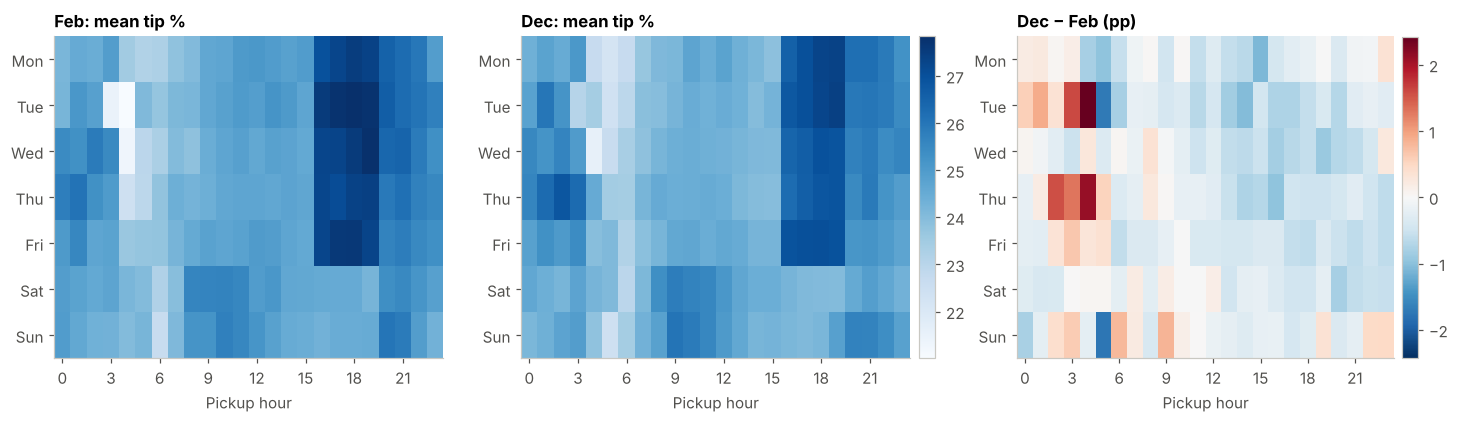

In [12]:
grid = s.pivot_table(index="dow", columns=["month_name", "hour"], values="tip_pct", aggfunc="mean")
vmin, vmax = grid.min().min(), grid.max().max()
gap = grid["Dec"] - grid["Feb"]
lim = np.nanmax(np.abs(gap.values))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, mn in zip(axes[:2], MONTHS2):
    im = ax.imshow(grid[mn], aspect="auto", cmap="Blues", vmin=vmin, vmax=vmax)
    ax.set_title(f"{mn}: mean tip %", fontsize=11)
fig.colorbar(im, ax=axes[:2], fraction=0.02, pad=0.01)
im2 = axes[2].imshow(gap, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("Dec − Feb (pp)", fontsize=11)
fig.colorbar(im2, ax=axes[2], fraction=0.04, pad=0.02)
for ax in axes:
    ax.set_yticks(range(7), tu.DOW_NAMES)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Pickup hour")
    ax.grid(False)
tu.save_fig(fig, "05a_hour_dow_heatmap")
plt.show()

## 5b · Tip % by hour 📊

Shaded bands are 95% confidence intervals.

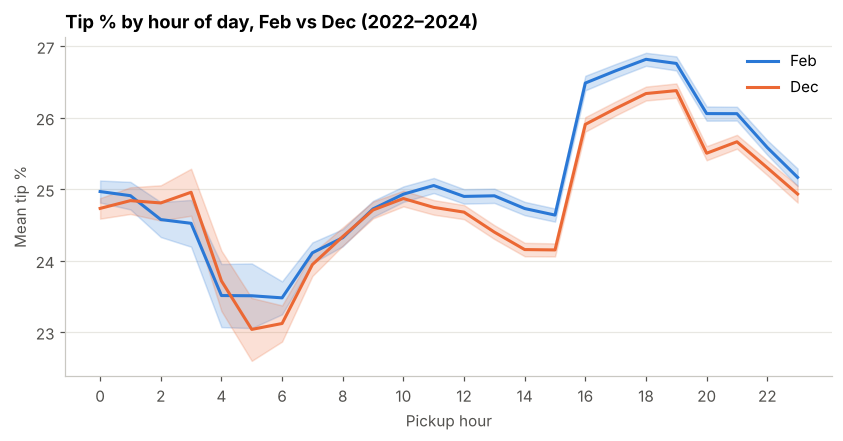

In [13]:
hr = tu.summarize(s, ["month_name", "hour"])
fig, ax = plt.subplots(figsize=(9, 4))
for mn in MONTHS2:
    d = hr[hr.month_name == mn]
    ax.plot(d.hour, d["mean"], color=tu.MONTH_COLORS[mn], label=mn)
    ax.fill_between(d.hour, d["mean"] - d.ci95, d["mean"] + d.ci95, color=tu.MONTH_COLORS[mn], alpha=0.2)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Pickup hour")
ax.set_ylabel("Mean tip %")
ax.set_title("Tip % by hour of day, Feb vs Dec (2022–2024)")
ax.legend()
tu.save_fig(fig, "05b_tip_by_hour")
plt.show()

## 5c · Tip % by pickup borough 📊

Boroughs with fewer than 1,000 sampled trips in either month are dropped.

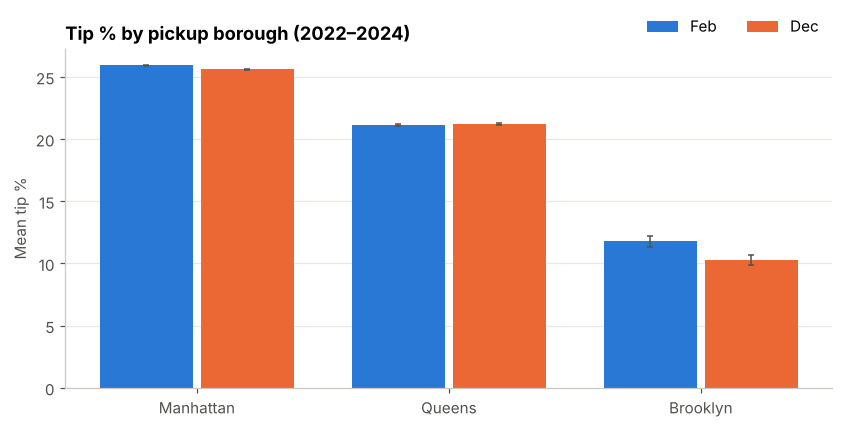

n             mean       zero_tip_pct      
month_name        Dec        Feb   Dec   Feb          Dec   Feb
pu_borough                                                     
Manhattan  680,645.00 690,797.00 25.62 25.92         3.90  3.47
Queens      63,358.00  54,268.00 21.21 21.16         7.62  7.19
Brooklyn     4,822.00   3,919.00 10.27 11.78        57.67 50.73

In [14]:
bor = tu.summarize(s, ["pu_borough", "month_name"])
keep = bor.groupby("pu_borough").n.min()
bor = bor[bor.pu_borough.isin(keep[keep >= 1000].index)]
order = bor.groupby("pu_borough").n.sum().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(9, 4))
tu.grouped_bar(ax, bor, "pu_borough", "month_name", "mean", tu.MONTH_COLORS, err="ci95",
               order=order, groups=MONTHS2)
ax.set_ylabel("Mean tip %")
ax.set_title("Tip % by pickup borough (2022–2024)")
tu.save_fig(fig, "05c_tip_by_borough")
plt.show()
bor.pivot(index="pu_borough", columns="month_name", values=["n", "mean", "zero_tip_pct"]).loc[order]

## 5d · Highest- and lowest-tipping pickup zones 📊 (full data)

Zones need at least 1,000 trips in **both** February and December (2022–2024 combined). Zones are ranked by their combined mean; the dots show each month.

78 zones qualify


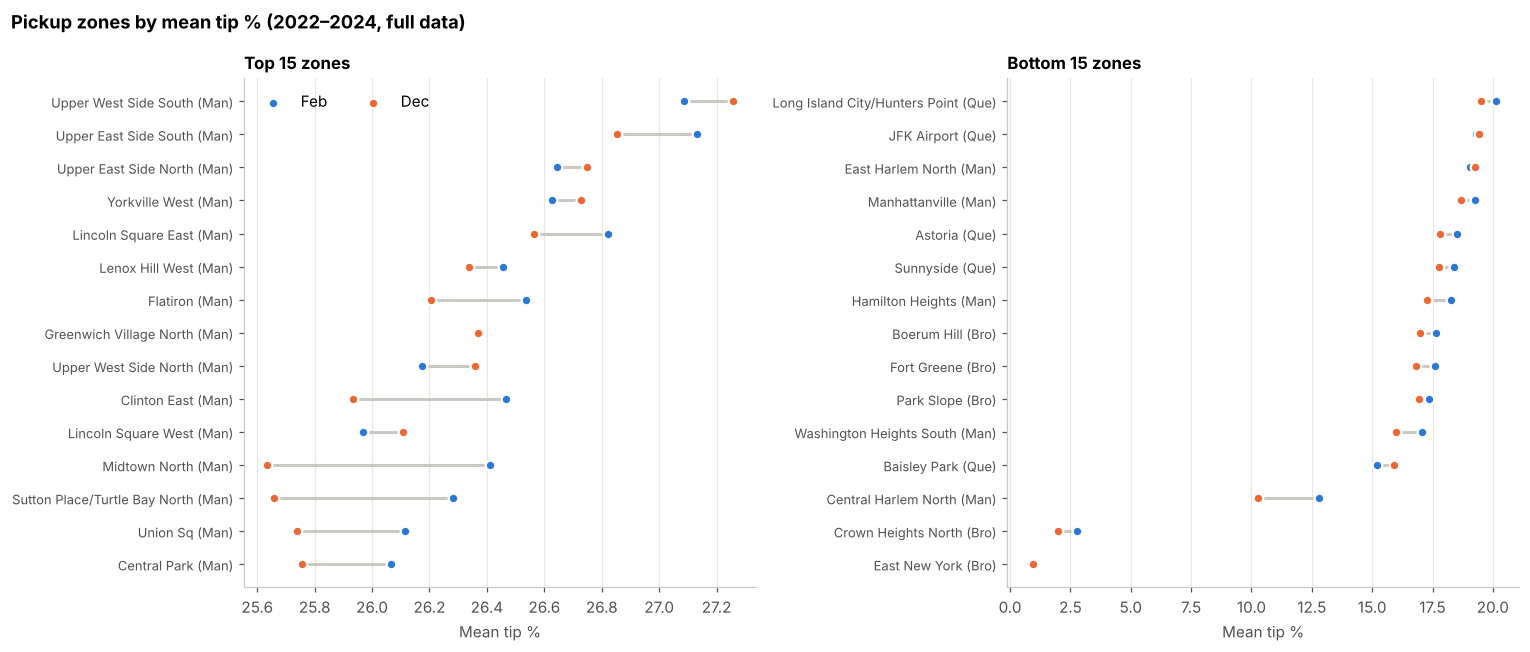

In [15]:
z = full_zone[full_zone.year.isin(tu.EDA_YEARS)].copy()
z["tip_sum"] = z["mean"] * z.n
zz = z.groupby(["PULocationID", "pu_zone", "pu_borough", "month_name"])[["n", "tip_sum"]].sum().reset_index()
zz["mean"] = zz.tip_sum / zz.n
wide = zz.pivot_table(index=["pu_zone", "pu_borough"], columns="month_name", values=["n", "mean"])
wide = wide[(wide["n"]["Feb"] >= 1000) & (wide["n"]["Dec"] >= 1000)]
wide["overall"] = (wide["mean"]["Feb"] * wide["n"]["Feb"] + wide["mean"]["Dec"] * wide["n"]["Dec"]) \
                  / (wide["n"]["Feb"] + wide["n"]["Dec"])
wide = wide.sort_values("overall")
print(f"{len(wide)} zones qualify")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, part, title in [(axes[0], wide.tail(15), "Top 15 zones"), (axes[1], wide.head(15), "Bottom 15 zones")]:
    labels = [f"{zn} ({b[:3]})" for zn, b in part.index]
    y = np.arange(len(part))
    ax.hlines(y, part["mean"]["Feb"], part["mean"]["Dec"], color="#c9c8c2", linewidth=2)
    for mn in MONTHS2:
        ax.scatter(part["mean"][mn], y, color=tu.MONTH_COLORS[mn], s=40, zorder=3,
                   label=mn, edgecolor="white", linewidth=1.5)
    ax.set_yticks(y, labels, fontsize=8.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Mean tip %")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", ncol=2)
fig.suptitle("Pickup zones by mean tip % (2022–2024, full data)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
tu.save_fig(fig, "05d_top_bottom_zones")
plt.show()

## 5e · Airport vs non-airport trips 📊

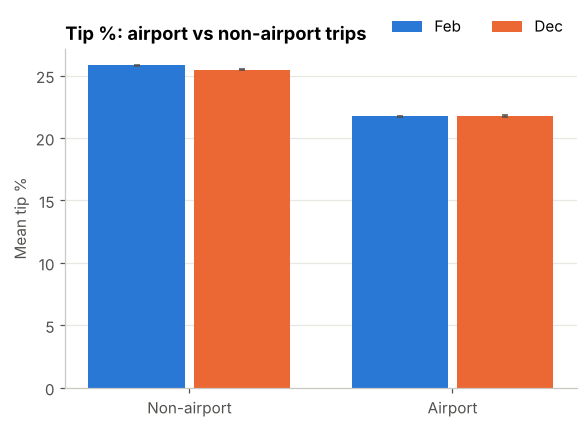

,trip type,month_name,n,mean,median,zero_tip_pct,tip20_pct
0,Non-airport,Dec,674616,25.48,26.25,4.60,77.31
1,Non-airport,Feb,687333,25.81,26.61,4.02,77.33
2,Airport,Dec,75384,21.77,23.17,5.59,73.60
3,Airport,Feb,62667,21.73,23.13,5.08,72.92


In [16]:
ap = tu.summarize(s, ["is_airport", "month_name"])
ap["trip type"] = ap.is_airport.map({True: "Airport", False: "Non-airport"})
fig, ax = plt.subplots(figsize=(6, 4))
tu.grouped_bar(ax, ap, "trip type", "month_name", "mean", tu.MONTH_COLORS, err="ci95",
               order=["Non-airport", "Airport"], groups=MONTHS2)
ax.set_ylabel("Mean tip %")
ax.set_title("Tip %: airport vs non-airport trips")
tu.save_fig(fig, "05e_tip_airport")
plt.show()
ap[["trip type", "month_name", "n", "mean", "median", "zero_tip_pct", "tip20_pct"]]

## 5f · Tip % by trip distance 📊

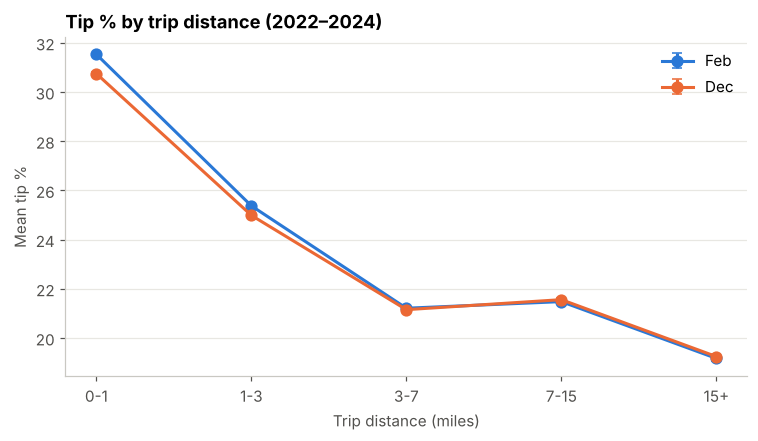

n             mean       zero_tip_pct     
month_name         Dec        Feb   Dec   Feb          Dec  Feb
dist_bucket                                                    
0-1         163,634.00 154,737.00 30.75 31.53         4.31 3.86
1-3         375,697.00 394,409.00 24.99 25.37         3.58 3.17
3-7         116,304.00 120,136.00 21.15 21.21         5.50 4.81
7-15         58,416.00  51,134.00 21.56 21.48         9.02 8.26
15+          35,949.00  29,584.00 19.24 19.17         8.59 7.96

In [17]:
db = tu.summarize(s, ["dist_bucket", "month_name"])
fig, ax = plt.subplots(figsize=(8, 4))
for mn in MONTHS2:
    d = db[db.month_name == mn]
    ax.errorbar(d.dist_bucket.astype(str), d["mean"], yerr=d.ci95, color=tu.MONTH_COLORS[mn],
                marker="o", markersize=7, capsize=3, label=mn)
ax.set_xlabel("Trip distance (miles)")
ax.set_ylabel("Mean tip %")
ax.set_title("Tip % by trip distance (2022–2024)")
ax.legend()
tu.save_fig(fig, "05f_tip_by_distance")
plt.show()
db.pivot(index="dist_bucket", columns="month_name", values=["n", "mean", "zero_tip_pct"])

## 5g · Holiday periods 📊

* **December:** Dec 24–31 vs the rest of December
* **February:** Presidents' Day long weekend (Sat–Mon) vs the rest of February

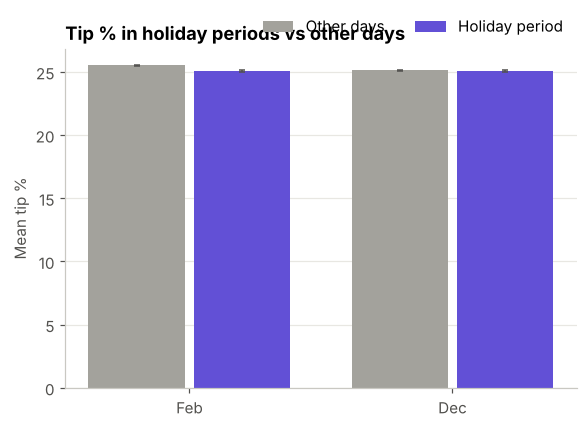

,month_name,period,n,mean,zero_tip_pct,tip20_pct
0,Dec,Other days,625412,25.11,4.45,77.00
1,Dec,Holiday period,124588,25.07,5.96,76.60
2,Feb,Other days,680812,25.51,4.08,76.91
3,Feb,Holiday period,69188,25.06,4.41,77.50


In [18]:
hol = tu.summarize(s, ["month_name", "is_holiday"])
hol["period"] = hol.is_holiday.map({True: "Holiday period", False: "Other days"})
fig, ax = plt.subplots(figsize=(6, 4))
tu.grouped_bar(ax, hol, "month_name", "period", "mean",
               {"Other days": tu.NEUTRAL, "Holiday period": "#6250d6"},
               err="ci95", order=MONTHS2)
ax.set_ylabel("Mean tip %")
ax.set_title("Tip % in holiday periods vs other days")
tu.save_fig(fig, "05g_tip_holiday")
plt.show()
hol[["month_name", "period", "n", "mean", "zero_tip_pct", "tip20_pct"]]

## 5h · All Feb vs Dec gaps in one table

`diff` = Dec − Feb mean tip % (percentage points) with a 95% CI. `meaningful` flags gaps at least `MEANINGFUL_GAP` in size.

In [19]:
def gap_rows(dim, col=None):
    out = []
    levels = [("All trips", s)] if col is None else [(lvl, g) for lvl, g in s.groupby(col, observed=True)]
    for lvl, g in levels:
        f, d = g[g.month_name == "Feb"].tip_pct, g[g.month_name == "Dec"].tip_pct
        if min(len(f), len(d)) < 1000:
            continue
        r = tu.diff_ci(f, d)
        out.append({"dimension": dim, "level": str(lvl), "n Feb": len(f), "n Dec": len(d),
                    "Feb mean": f.mean(), "Dec mean": d.mean(), **r})
    return out

rows = gap_rows("overall")
for dim, col in [("borough", "pu_borough"), ("airport trip", "is_airport"),
                 ("distance", "dist_bucket"), ("weekend", "is_weekend"),
                 ("night (10pm-6am)", "is_night"), ("holiday period", "is_holiday")]:
    rows += gap_rows(dim, col)
gaps = pd.DataFrame(rows)
gaps["meaningful"] = gaps["diff"].abs() >= MEANINGFUL_GAP
gaps.to_csv(tu.DOCS / "step5_feb_dec_gaps.csv", index=False)
gaps.set_index(["dimension", "level"])

n Feb   n Dec  Feb mean  Dec mean  diff  ci_low  \
dimension        level                                                         
overall          All trips  750000  750000     25.47     25.11 -0.36   -0.39   
borough          Brooklyn     3919    4822     11.78     10.27 -1.51   -2.08   
                 Manhattan  690797  680645     25.92     25.62 -0.30   -0.34   
                 Queens      54268   63358     21.16     21.21  0.05   -0.06   
airport trip     False      687333  674616     25.81     25.48 -0.33   -0.36   
                 True        62667   75384     21.73     21.77  0.04   -0.06   
distance         0-1        154737  163634     31.53     30.75 -0.78   -0.87   
                 1-3        394409  375697     25.37     24.99 -0.39   -0.43   
                 3-7        120136  116304     21.21     21.15 -0.06   -0.13   
                 7-15        51134   58416     21.48     21.56  0.08   -0.04   
                 15+         29584   35949     19.17     19.24  0.07   -0.06   
weekend          False      544185  538579     25.70     25.28 -0.42   -0.46   
                 True       205815  211421     24.85     24.66 -0.19   -0.25   
night (10pm-6am) False      626552  619288     25.54     25.15 -0.40   -0.43   
                 True       123448  130712     25.08     24.91 -0.17   -0.25   
holiday period   False      680812  625412     25.51     25.11 -0.39   -0.43   
                 True        69188  124588     25.06     25.07  0.01   -0.09   

                            ci_high  cohens_d  meaningful  
dimension        level                                     
overall          All trips    -0.33     -0.03       False  
borough          Brooklyn     -0.94     -0.11        True  
                 Manhattan    -0.27     -0.03       False  
                 Queens        0.16      0.00       False  
airport trip     False        -0.29     -0.03       False  
                 True          0.13      0.00       False  
distance         0-1          -0.70     -0.06        True  
                 1-3          -0.34     -0.04       False  
                 3-7           0.01     -0.01       False  
                 7-15          0.20      0.01       False  
                 15+           0.21      0.01       False  
weekend          False        -0.38     -0.04       False  
                 True         -0.13     -0.02       False  
night (10pm-6am) False        -0.36     -0.04       False  
                 True         -0.08     -0.02       False  
holiday period   False        -0.36     -0.04       False  
                 True          0.11      0.00       False